---
# Executed by scripts/export_gw_examples.py; the docs build shows the stored outputs.
execute:
  skip: true
---
# 2. Fitting the GW catalog with TGMMs

This page was generated from [`notebooks/gw/02_gw_tgmm_fitting.py`](https://github.com/Potatoasad/astroinfer/blob/main/notebooks/gw/02_gw_tgmm_fitting.py), a marimo notebook. Sliders and other controls are shown at their default values. To change them, run the notebook with `uv run marimo edit notebooks/gw/02_gw_tgmm_fitting.py`.

Each event's posterior is compressed into a truncated Gaussian mixture,

$$p(\theta\mid d_i) \approx \sum_{k=1}^{K} w_k\,\mathcal{N}_{[a,b]}\!\left(T(\theta)\mid\mu_k,\Sigma_k\right),$$

whose Gaussian kernels a population analysis can integrate against analytically. In astroinfer a
TGMM fit is a *representation* of the catalog, alongside the built-in `raw` one. You register a
`TGMMFitter` under a name, `catalog.fit(name)` fits the events that need it, and
`catalog.dataproduct(representation=name)` stacks the fits for inference.

This notebook uses the catalog saved by notebook 1.

In [1]:
import sys
from pathlib import Path

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "scripts" / "marimo_docs_shim.py").is_file())
sys.path[:0] = [str(ROOT / "notebooks/gw"), str(ROOT / "scripts")]

import marimo_docs_shim
marimo_docs_shim.set_notebook_dir(ROOT / "notebooks/gw")
sys.modules["marimo"] = marimo_docs_shim

# marimo shows a figure only when a cell returns it. Stop Jupyter from also showing every
# figure a cell creates, and close them once the cell has run.
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import flush_figures
get_ipython().run_line_magic("matplotlib", "inline")
try:
    get_ipython().events.unregister("post_execute", flush_figures)
except ValueError:
    pass
get_ipython().events.register("post_execute", lambda: plt.close("all"))

# Show astroinfer objects with their HTML display (as Jupyter does), not the short markdown one.
get_ipython().display_formatter.formatters["text/markdown"].enabled = False
# Open every object display, so readers see the contents without having to click.
import astroinfer.display
astroinfer.display.set_options(expanded=True)


In [2]:
import jax

jax.config.update("jax_enable_x64", True)

import time
import warnings
from pathlib import Path

import marimo as mo
import numpy as np
import pandas as pd
import plot_helper as ph
from astroinfer import Catalog

from astroinfer_tgmm import TGMMConfig, TGMMFitter, TransformationSpec
from astroinfer_tgmm.plotting import plot_comparison

ph.restore_plot_defaults()
ph.set_plot_defaults(latex_font_size=16, usetex=True)

# The notebook's own folder (mo.notebook_dir() is the cwd when run as a script).
try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path(mo.notebook_dir())
CATALOG_DIR = NOTEBOOK_DIR.parent / "data" / "gw_catalog"

# Quiet, deterministic fits; method/backend as in tgm's defaults for this project.
FIT_KWARGS = dict(method="hybrid", backend="jax", progress=False)

LABELS = dict(mass_1_source=r"$m_1$", mass_ratio=r"$q$", redshift=r"$z$",
              chi_1=r"$\chi_1$", chi_2=r"$\chi_2$", cos_tilt_1=r"$\cos\theta_1$",
              cos_tilt_2=r"$\cos\theta_2$")

In [3]:
mo.stop(not CATALOG_DIR.exists(),
        mo.md(f"No catalog at `{CATALOG_DIR}`: run `01_gw_mock_catalog.py` first."))
catalog = Catalog.load(CATALOG_DIR)
catalog

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


Detected Jupyter notebook. Loading juliacall extension. Set `PYSR_AUTOLOAD_EXTENSIONS=no` to disable.


Catalog(n_events=20, columns=['mass_1_source', 'mass_ratio', 'chi_1', 'chi_2', 'cos_tilt_1', 'cos_tilt_2', 'redshift'], representations=['raw', 'masses', 'spins', 'masses_log'])

## A TGMM configuration for the masses and redshift

`TGMMConfig` holds every setting that determines a fit. It is plain JSON, so it is saved with
the catalog. The settings used here are:

- `columns`: the posterior variables to fit, here $m_1$, $q$ and $z$.
- `K`, `cov` and `block_structure`: $K$ components with full covariance matrices, except that
  $z$ is in its own block, so $(m_1, q)$ and $z$ are independent within each component.
- `limits`: the truncation box. Using the support of the PE prior keeps every component inside
  it.
- `analytic_columns` and `sampled_columns`: what the data product contains. Analytic columns
  export the kernel parameters $(\mu_k, \sigma_k, \rho_k)$. Sampled columns export `N` draws per
  component, together with the PE prior of the fitted columns.

The PE prior of these three columns is computed from the `log_prior[...]` factors that PE
stored, and the fit carries it as `prior`.

In [4]:
mass_config = TGMMConfig(
    columns=["mass_1_source", "mass_ratio", "redshift"],
    K=4, cov="full", block_structure=[0, 0, 1],
    limits={"mass_1_source": (2.0, 120.0), "mass_ratio": (0.05, 1.0), "redshift": (0.0, 1.5)},
    analytic_columns=["mass_1_source", "mass_ratio"], sampled_columns=["redshift"], N=500,
    fit_kwargs=FIT_KWARGS,
)
mass_config

TGMMConfig(columns=('mass_1_source', 'mass_ratio', 'redshift'), K=4, cov='full', block_structure=(0, 0, 1), carry_columns=(), quantiled_columns=(), n_quantiles=1000, quantile_padding=0.001, limits={'mass_1_source': (2.0, 120.0), 'mass_ratio': (0.05, 1.0), 'redshift': (0.0, 1.5)}, transformation=None, n_samples=None, log_weight_column=None, seed=0, fit_kwargs={'method': 'hybrid', 'backend': 'jax', 'progress': False}, analytic_columns=('mass_1_source', 'mass_ratio'), sampled_columns=('redshift',), N=500)

`TGMMFitter` holds the default configuration, the per-event overrides and the retry policy. A
fit that puts a component almost entirely outside the box is repeated with the next seed. After
the fitter is registered on the catalog, `catalog.fit` fits every event that has no fit yet or
whose fit is stale.

In [5]:
catalog.register_representation("masses", TGMMFitter(mass_config), overwrite=True)
_t0 = time.perf_counter()
masses_fitted = catalog.fit("masses")
mo.vstack([
    mo.md(f"Fitted {len(masses_fitted)} events in {time.perf_counter() - _t0:.1f} s. "
          "Fits already in the saved catalog are reused."),
    catalog,
])

Catalog(n_events=20, columns=['mass_1_source', 'mass_ratio', 'chi_1', 'chi_2', 'cos_tilt_1', 'cos_tilt_2', 'redshift'], representations=['raw', 'masses', 'spins', 'masses_log'])

## One fit

The expanded fit shows its components, truncation box and diagnostics. The corner plot compares
the posterior with draws from the TGMM and marks the injected truth.

In [6]:
event = mo.ui.dropdown(catalog.eventnames, value=catalog.eventnames[0], label="event")
event

TGMMFit(K=4, columns=['mass_1_source', 'mass_ratio', 'redshift'], image_columns=['mass_1_source', 'mass_ratio', 'redshift'], seed=0)

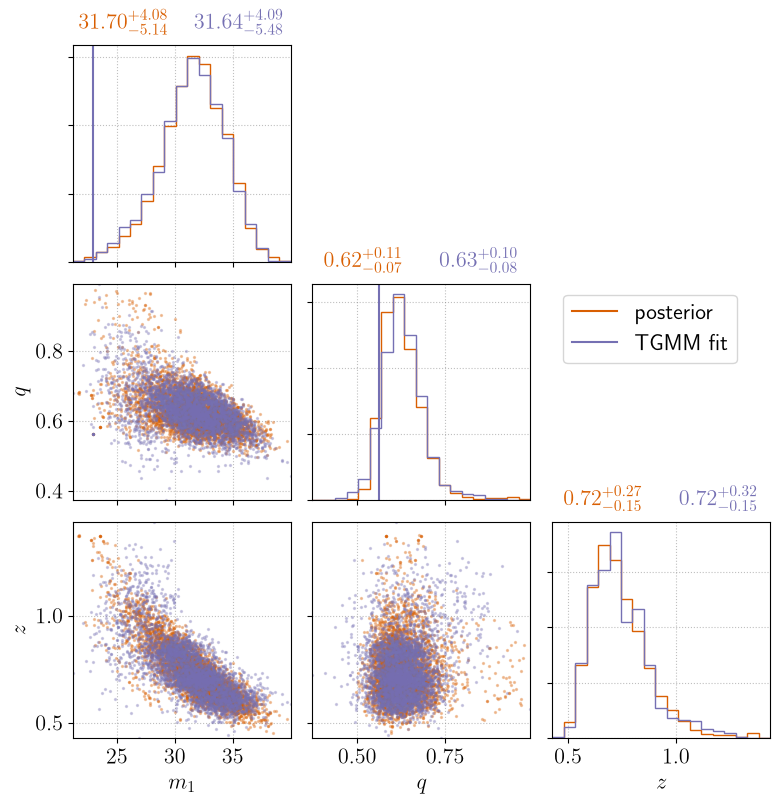

In [7]:
_ = masses_fitted
_fit = catalog.get_fit(event.value, "masses")
_truth = catalog.posterior(event.value).metadata["injected_true"]
_fig = plot_comparison(catalog, event.value, name="masses", labels=LABELS,
                       truth={c: _truth[c] for c in _fit.config.columns})
mo.vstack([_fit, _fig])

## Per-event configurations and stale fits

Some events need a different configuration, for example more components. Overrides are stored
in the fitter. Changing a setting that affects the fit makes that event's fit *stale*, and the
next `catalog.fit` refits only that event. Settings that only shape the data product
(`analytic_columns`, `sampled_columns` and `N`) never make a fit stale.

In [8]:
_ = masses_fitted
override_event = catalog.eventnames[0]
_fitter = catalog.fitter("masses")

_fitter.update_event_config(override_event, N=200)          # data product only
stale_after_n = catalog.stale("masses")
_fitter.update_event_config(override_event, K=8)            # changes the fit
stale_after_k = catalog.stale("masses")
refit = catalog.fit("masses")

mo.vstack([
    mo.md(f"""
- stale after changing `N` for `{override_event}`: `{stale_after_n}`
- stale after changing `K`: `{stale_after_k}`
- refit: `{refit}`; it now has K = {catalog.get_fit(override_event, "masses").K}
"""),
    _fitter,
])

TGMMFitter(K=4, columns=['mass_1_source', 'mass_ratio', 'redshift'], event_configs=['event_01'])

## The data product

`catalog.dataproduct(representation="masses")` stacks the events' data products along a leading
event axis. Events can have different numbers of components. Every event is padded to the
largest $K$ with components of weight 0, which copy the event's heaviest component so that no
value is NaN. Here the first event, with $K = 8$, sets the size.

Passing `N` sets the number of draws per component for every event. Without it, each event uses
the `N` of its own configuration, and the products can only be stacked if those agree.

In [9]:
_ = refit
masses_product = catalog.dataproduct(representation="masses", N=500)
_weights = np.asarray(masses_product["weights"])
mo.vstack([
    pd.DataFrame({k: [str(tuple(v.shape))] for k, v in masses_product.items()}, index=["shape"]).T,
    mo.md("Component weights of the first three events (padded components have weight 0):"),
    pd.DataFrame(_weights[:3], index=catalog.eventnames[:3]).round(3),
])

,shape
mass_1_source,"(20, 8, 500)"
mass_ratio,"(20, 8, 500)"
redshift,"(20, 8, 500)"
prior,"(20, 8, 500)"
mass_1_source_mu_kernel,"(20, 8)"
mass_1_source_sigma_kernel,"(20, 8)"
mass_1_source_rho_kernel,"(20, 8)"
mass_ratio_rho_kernel,"(20, 8)"
mass_ratio_mu_kernel,"(20, 8)"
mass_ratio_sigma_kernel,"(20, 8)"


,0,1,2,3,4,5,6,7
event_01,0.207,0.119,0.071,0.144,0.188,0.091,0.152,0.026
event_02,0.290,0.176,0.247,0.286,0.000,0.000,0.000,0.000
event_03,0.398,0.340,0.186,0.076,0.000,0.000,0.000,0.000


## A second representation for the spins

A catalog can hold any number of named representations. This one is a four-dimensional fit of
the spin magnitudes and tilt cosines, with $(\chi_1, \chi_2)$ and $(\cos\theta_1, \cos\theta_2)$
in separate covariance blocks and all four columns analytic.

In [10]:
spin_config = TGMMConfig(
    columns=["chi_1", "chi_2", "cos_tilt_1", "cos_tilt_2"],
    K=4, cov="full", block_structure=[0, 0, 1, 1],
    limits={"chi_1": (0.0, 1.0), "chi_2": (0.0, 1.0), "cos_tilt_1": (-1.0, 1.0), "cos_tilt_2": (-1.0, 1.0)},
    analytic_columns=["chi_1", "chi_2", "cos_tilt_1", "cos_tilt_2"],
    fit_kwargs=FIT_KWARGS,
)
catalog.register_representation("spins", TGMMFitter(spin_config), overwrite=True)
with warnings.catch_warnings(record=True) as _caught:
    warnings.simplefilter("always")
    _fitted = catalog.fit("spins", errors="warn")
spin_failures = catalog.missing("spins") + catalog.stale("spins")
mo.md(f"Fitted {len(_fitted)} events. "
      + (f"These events failed, because every retry put a component outside the box: "
         f"`{spin_failures}`" if spin_failures else "No event failed."))

Spin posteriors pile up against the edges of $[0, 1]$, and with $K = 4$ the fitter can put a
component almost entirely outside the box. When every retry with a new seed does the same,
`catalog.fit(..., errors="warn")` reports the event and fits the others. Overriding the events
that failed to use fewer components fixes them, and only those events are refit.

In [11]:
for _eventname in spin_failures:
    catalog.fitter("spins").update_event_config(_eventname, K=3)
spins_fitted = catalog.fit("spins")
mo.vstack([mo.md(f"Refit with K = 3: `{spins_fitted}`. Stale or missing now: "
                 f"`{catalog.missing('spins') + catalog.stale('spins')}`"),
           catalog.fitter("spins")])

TGMMFitter(K=4, columns=['chi_1', 'chi_2', 'cos_tilt_1', 'cos_tilt_2'], event_configs=[])

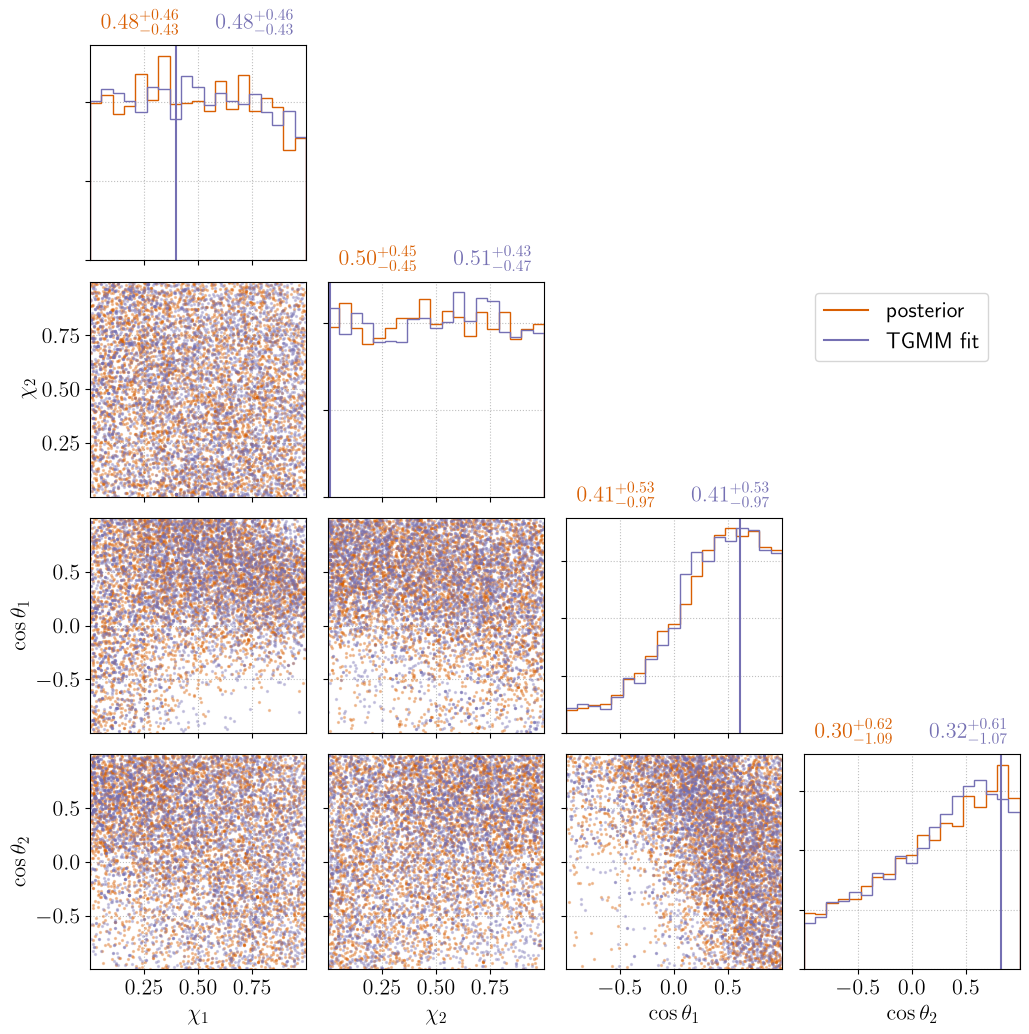

In [12]:
_ = spins_fitted
_truth = catalog.posterior(event.value).metadata["injected_true"]
_columns = ["chi_1", "chi_2", "cos_tilt_1", "cos_tilt_2"]
plot_comparison(catalog, event.value, name="spins", labels=LABELS, truth={c: _truth[c] for c in _columns})

## Fitting in transformed coordinates

A `TransformationSpec` changes coordinates before fitting. Its maps are written as `lambda`
strings, so the configuration can still be saved. Here $m_1$ is fitted as $\ln m_1$, and $z$ is
quantile-transformed for each event, which takes the box for $z$ from the data, so it needs no
limits. Limits are given in the fitted coordinates (`log_mass_1_source`), and the fit's kernels
are in those coordinates too, as the "fitted as" row of the fit's display shows.

In [13]:
log_config = TGMMConfig(
    columns=["mass_1_source", "mass_ratio", "redshift"],
    transformation=TransformationSpec(
        forward_transformation="lambda m1, q, z: (jnp.log(m1), q, z)",
        inverse_transformation="lambda log_m1, q, z: (jnp.exp(log_m1), q, z)",
        transformed_columns=["log_mass_1_source", "mass_ratio", "redshift"],
    ),
    quantiled_columns=["redshift"],
    K=4, cov="full", block_structure=[0, 0, 1],
    limits={"log_mass_1_source": (float(np.log(2.0)), float(np.log(120.0))), "mass_ratio": (0.05, 1.0)},
    analytic_columns=["mass_1_source", "mass_ratio"], sampled_columns=["redshift"], N=500,
    fit_kwargs=FIT_KWARGS,
)
catalog.register_representation("masses_log", TGMMFitter(log_config), overwrite=True)
log_fitted = catalog.fit("masses_log")
log_config

TGMMConfig(columns=('mass_1_source', 'mass_ratio', 'redshift'), K=4, cov='full', block_structure=(0, 0, 1), carry_columns=(), quantiled_columns=('redshift',), n_quantiles=1000, quantile_padding=0.001, limits={'log_mass_1_source': (0.6931471805599453, 4.787491742782046), 'mass_ratio': (0.05, 1.0)}, transformation=TransformationSpec(forward_transformation='lambda m1, q, z: (jnp.log(m1), q, z)', inverse_transformation='lambda log_m1, q, z: (jnp.exp(log_m1), q, z)', transformed_columns=('log_mass_1_source', 'mass_ratio', 'redshift'), extra_funcs=()), n_samples=None, log_weight_column=None, seed=0, fit_kwargs={'method': 'hybrid', 'backend': 'jax', 'progress': False}, analytic_columns=('mass_1_source', 'mass_ratio'), sampled_columns=('redshift',), N=500)

TGMMFit(K=4, columns=['mass_1_source', 'mass_ratio', 'redshift'], image_columns=['log_mass_1_source', 'mass_ratio', 'redshift_quantile'], seed=0)

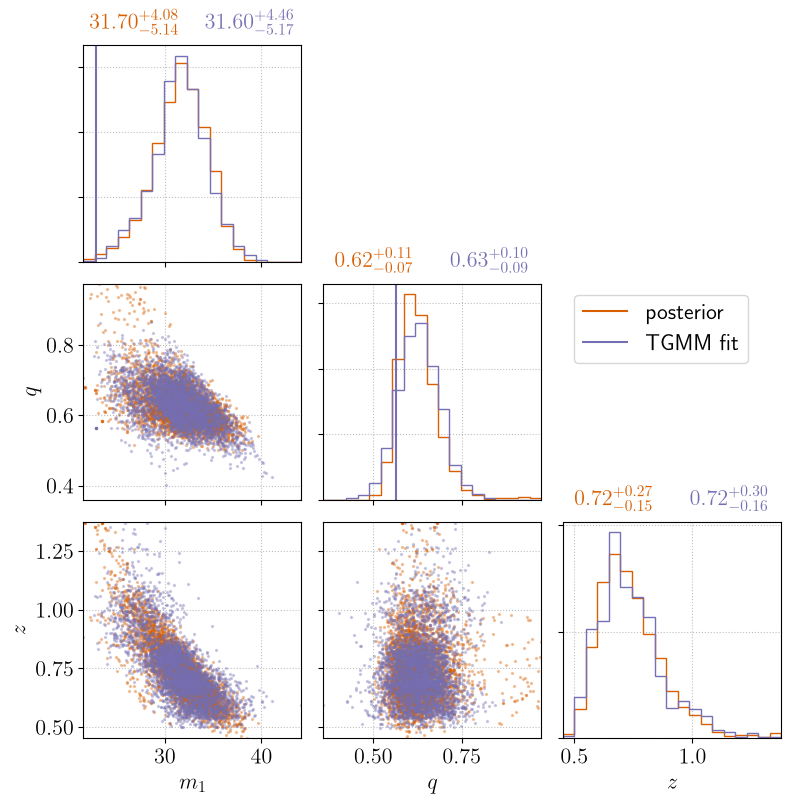

In [14]:
_ = log_fitted
_truth = catalog.posterior(event.value).metadata["injected_true"]
mo.vstack([
    catalog.get_fit(event.value, "masses_log"),
    plot_comparison(catalog, event.value, name="masses_log", labels=LABELS,
                    truth={c: _truth[c] for c in ["mass_1_source", "mass_ratio", "redshift"]}),
])

## Saving and loading

`catalog.save(root)` writes to disk only when it is called, and only what has changed since the
last save. Each representation stores its fitter, with the default configuration and the
per-event overrides, and one folder per fitted event, holding `gmm.h5` and the configuration
the event was fitted with. Every fit is loaded together with its fit key, so the catalog still
knows which fits are stale.

In [15]:
_ = (refit, spins_fitted, log_fitted)
catalog.save(CATALOG_DIR)
reloaded = Catalog.load(CATALOG_DIR)
mo.vstack([
    mo.md("Stale fits after reload: "
          + ", ".join(f"`{name}`: {reloaded.stale(name)}" for name in reloaded.representations
                      if name != "raw")),
    reloaded,
])

Catalog(n_events=20, columns=['mass_1_source', 'mass_ratio', 'chi_1', 'chi_2', 'cos_tilt_1', 'cos_tilt_2', 'redshift'], representations=['raw', 'masses', 'spins', 'masses_log'])